In [ ]:
pip install numpy matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 13.5 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 13.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 13.4 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 12.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 13.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 13.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [matplotlib]3 [matplotlib]n]
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.



Datos generados:
Total de puntos: 1900
Puntos de clusters: 1800
Outliers: 100


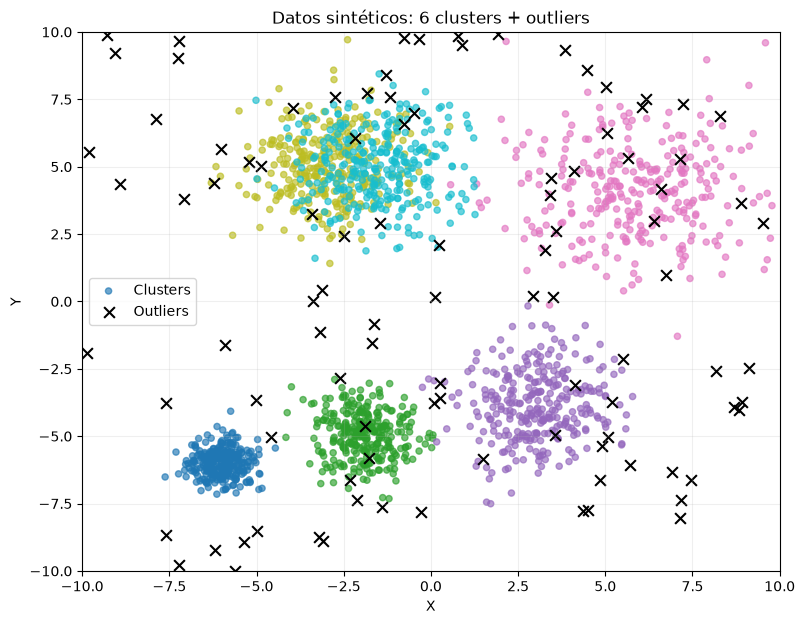


Después de remover outliers:
Puntos utilizados: 1800
Ejecutando K-means con K = 2
Ejecutando K-means con K = 3
Ejecutando K-means con K = 4
Ejecutando K-means con K = 5
Ejecutando K-means con K = 6
Ejecutando K-means con K = 7
Ejecutando K-means con K = 8
Ejecutando K-means con K = 9
Ejecutando K-means con K = 10
Ejecutando K-means con K = 11
Ejecutando K-means con K = 12


RESULTADOS DEL EXPERIMENTO
K    WCSS              Silhouette        ARI               
----------------------------------------------------------------------
2    31330.77          0.5562            0.3291            
3    17976.70          0.5942            0.4634            
4    7866.01           0.6394            0.6627            
5    5201.74           0.6702            0.8021            
6    4361.94           0.5425            0.8133            
7    3831.26           0.5000            0.7680            
8    3424.30           0.4979            0.7372            
9    3099.57           0.5018            0.7

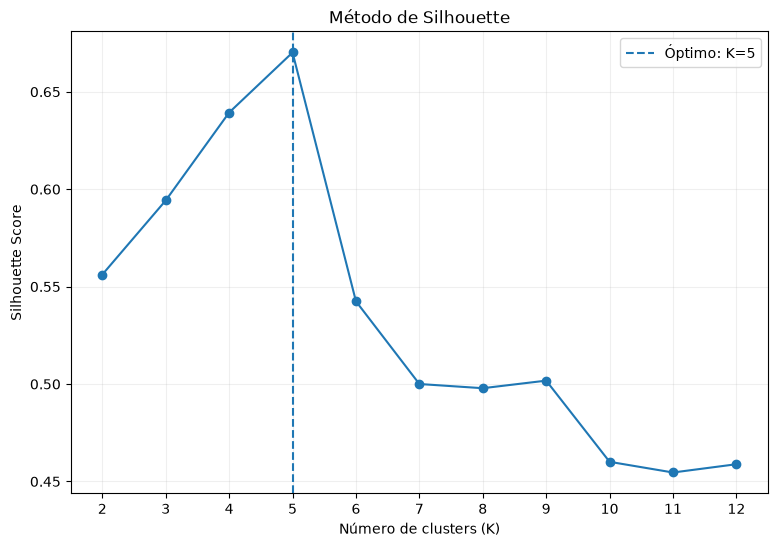

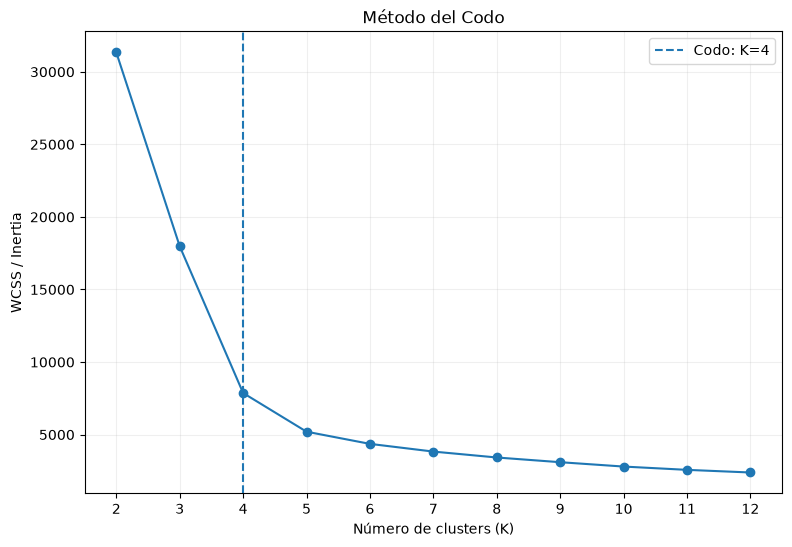

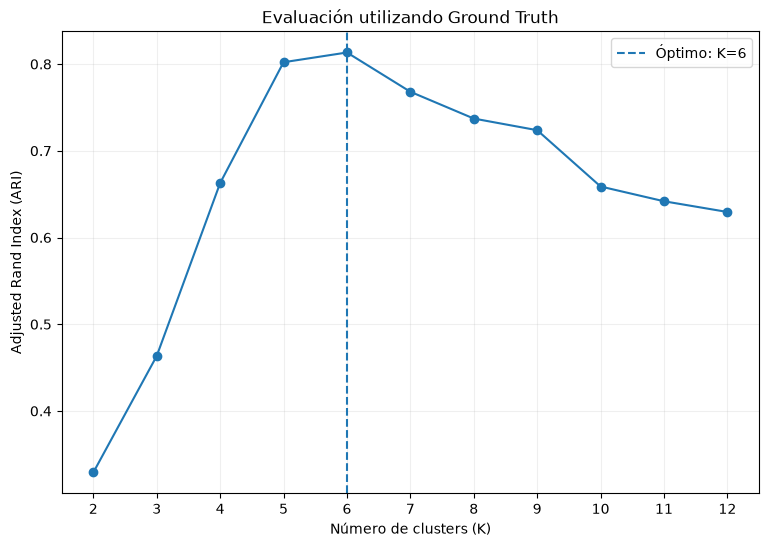

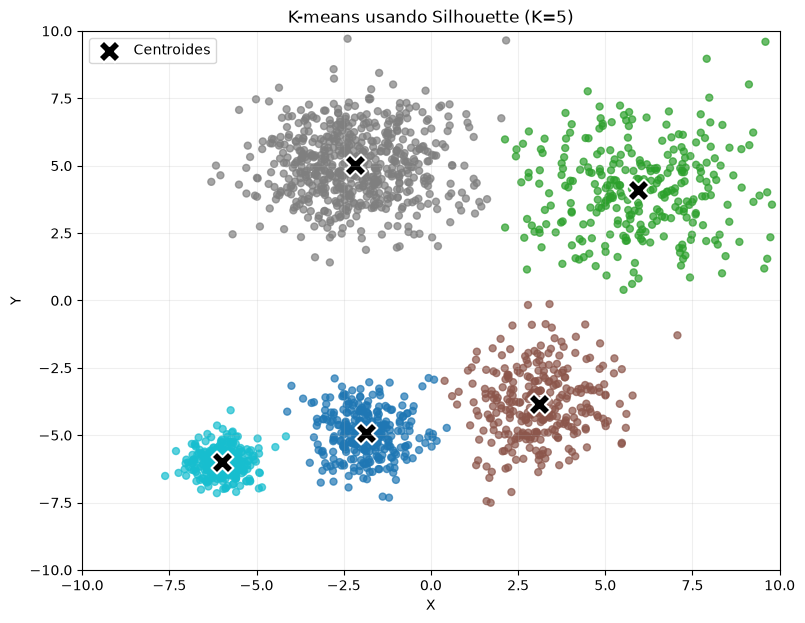

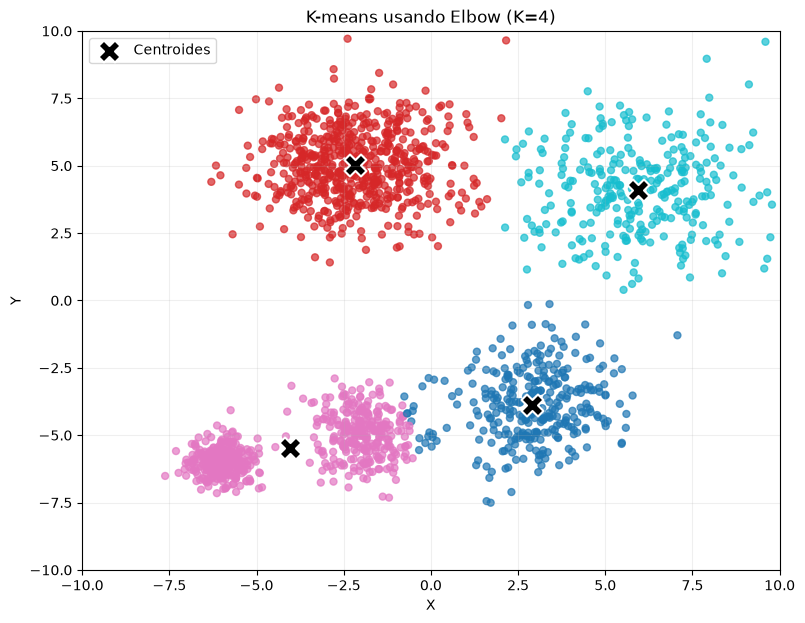

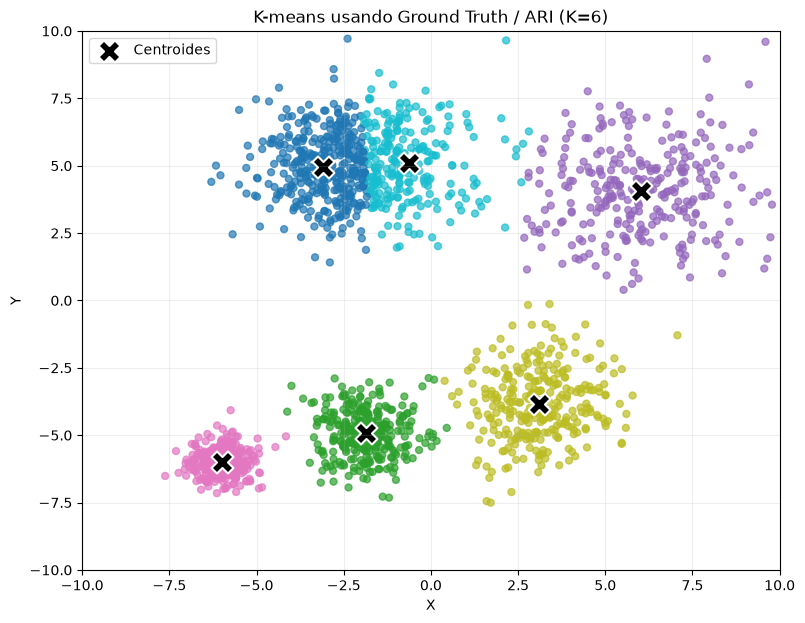

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

N_POINTS_PER_CLUSTER = 300
N_OUTLIERS = 100

MIN_VALUE = -10
MAX_VALUE = 10

K_VALUES = range(2, 13)


# ============================================================
# 2. GENERACIÓN DE DATOS
# ============================================================

def generate_gaussian_cluster(center, std, n_points):
    """
    Genera un cluster gaussiano isotrópico.

    center: tupla (x, y)
    std: desviación estándar
    n_points: número de puntos
    """

    points = np.random.normal(
        loc=center,
        scale=std,
        size=(n_points, 2)
    )

    # Nos aseguramos de que todos los puntos estén
    # dentro del rango [-10, 10].
    while np.any(points < MIN_VALUE) or np.any(points > MAX_VALUE):

        invalid = (
            (points[:, 0] < MIN_VALUE) |
            (points[:, 0] > MAX_VALUE) |
            (points[:, 1] < MIN_VALUE) |
            (points[:, 1] > MAX_VALUE)
        )

        n_invalid = np.sum(invalid)

        points[invalid] = np.random.normal(
            loc=center,
            scale=std,
            size=(n_invalid, 2)
        )

    return points


def generate_dataset():
    """
    Genera los 6 clusters y los outliers.
    """

    # --------------------------------------------------------
    # Centros y desviaciones estándar
    # --------------------------------------------------------
    #
    # Los clusters 5 y 6 están deliberadamente cerca
    # para producir una superposición parcial.
    #
    cluster_parameters = [
        ((-6, -6), 0.5),
        ((-2, -5), 0.8),
        ((3, -4), 1.2),
        ((6, 4), 1.8),
        ((-3, 5), 1.2),
        ((-1.5, 5), 1.2)
    ]

    all_points = []
    all_labels = []

    # --------------------------------------------------------
    # Generar los 6 clusters
    # --------------------------------------------------------

    for cluster_id, (center, std) in enumerate(cluster_parameters):

        points = generate_gaussian_cluster(
            center=center,
            std=std,
            n_points=N_POINTS_PER_CLUSTER
        )

        all_points.append(points)

        # Ground truth
        labels = np.full(
            N_POINTS_PER_CLUSTER,
            cluster_id
        )

        all_labels.append(labels)

    # --------------------------------------------------------
    # Generar outliers uniformemente entre -10 y 10
    # --------------------------------------------------------

    outliers = np.random.uniform(
        MIN_VALUE,
        MAX_VALUE,
        size=(N_OUTLIERS, 2)
    )

    outlier_labels = np.full(
        N_OUTLIERS,
        -1
    )

    all_points.append(outliers)
    all_labels.append(outlier_labels)

    # --------------------------------------------------------
    # Combinar todo
    # --------------------------------------------------------

    X = np.vstack(all_points)
    y = np.concatenate(all_labels)

    return X, y


# ============================================================
# 3. VISUALIZAR DATOS ORIGINALES
# ============================================================

def plot_original_data(X, y):

    plt.figure(figsize=(9, 7))

    # Puntos pertenecientes a los clusters
    mask = y != -1

    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        c=y[mask],
        cmap="tab10",
        s=20,
        alpha=0.65,
        label="Clusters"
    )

    # Outliers
    outlier_mask = y == -1

    plt.scatter(
        X[outlier_mask, 0],
        X[outlier_mask, 1],
        c="black",
        marker="x",
        s=60,
        label="Outliers"
    )

    plt.xlim(MIN_VALUE, MAX_VALUE)
    plt.ylim(MIN_VALUE, MAX_VALUE)

    plt.xlabel("X")
    plt.ylabel("Y")

    plt.title("Datos sintéticos: 6 clusters + outliers")

    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()


# ============================================================
# 4. REMOVER OUTLIERS
# ============================================================

def remove_outliers(X, y):

    mask = y != -1

    X_clean = X[mask]
    y_clean = y[mask]

    return X_clean, y_clean


# ============================================================
# 5. EJECUTAR K-MEANS PARA K = 2,...,12
# ============================================================

def run_kmeans_experiment(X, y_true):

    inertias = []
    silhouette_scores = []
    ari_scores = []

    models = {}
    predictions = {}

    for k in K_VALUES:

        print(f"Ejecutando K-means con K = {k}")

        kmeans = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=20
        )

        labels = kmeans.fit_predict(X)

        # -----------------------------------------------
        # WCSS / Inertia
        # -----------------------------------------------

        inertias.append(kmeans.inertia_)

        # -----------------------------------------------
        # Silhouette
        # -----------------------------------------------

        silhouette = silhouette_score(
            X,
            labels
        )

        silhouette_scores.append(silhouette)

        # -----------------------------------------------
        # Adjusted Rand Index
        # -----------------------------------------------

        ari = adjusted_rand_score(
            y_true,
            labels
        )

        ari_scores.append(ari)

        models[k] = kmeans
        predictions[k] = labels

    return (
        inertias,
        silhouette_scores,
        ari_scores,
        models,
        predictions
    )


# ============================================================
# 6. MÉTODO DEL CODO
# ============================================================

def find_elbow(k_values, inertias):
    """
    Encuentra automáticamente el punto del codo utilizando
    la distancia máxima a la línea que conecta el primer
    y último punto.
    """

    x = np.array(list(k_values))
    y = np.array(inertias)

    # Normalizamos X e Y
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())

    # Primer y último punto
    x1 = x_norm[0]
    y1 = y_norm[0]

    x2 = x_norm[-1]
    y2 = y_norm[-1]

    # Distancia perpendicular a la línea
    distances = np.abs(
        (y2 - y1) * x_norm
        - (x2 - x1) * y_norm
        + x2 * y1
        - y2 * x1
    ) / np.sqrt(
        (y2 - y1) ** 2
        + (x2 - x1) ** 2
    )

    elbow_index = np.argmax(distances)

    return x[elbow_index]


# ============================================================
# 7. OBTENER LOS K ÓPTIMOS
# ============================================================

def get_optimal_values(
    silhouette_scores,
    ari_scores,
    inertias
):

    k_values = np.array(list(K_VALUES))

    # -----------------------------------------------
    # Silhouette
    # -----------------------------------------------

    silhouette_index = np.argmax(
        silhouette_scores
    )

    best_k_silhouette = k_values[silhouette_index]

    # -----------------------------------------------
    # Ground truth / ARI
    # -----------------------------------------------

    ari_index = np.argmax(
        ari_scores
    )

    best_k_ari = k_values[ari_index]

    # -----------------------------------------------
    # Elbow
    # -----------------------------------------------

    best_k_elbow = find_elbow(
        K_VALUES,
        inertias
    )

    return (
        best_k_silhouette,
        best_k_elbow,
        best_k_ari
    )


# ============================================================
# 8. GRAFICAR SILHOUETTE
# ============================================================

def plot_silhouette(silhouette_scores):

    k_values = list(K_VALUES)

    best_k = k_values[
        np.argmax(silhouette_scores)
    ]

    plt.figure(figsize=(9, 6))

    plt.plot(
        k_values,
        silhouette_scores,
        marker="o"
    )

    plt.axvline(
        best_k,
        linestyle="--",
        label=f"Óptimo: K={best_k}"
    )

    plt.xlabel("Número de clusters (K)")
    plt.ylabel("Silhouette Score")

    plt.title("Método de Silhouette")

    plt.xticks(k_values)

    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()


# ============================================================
# 9. GRAFICAR MÉTODO DEL CODO
# ============================================================

def plot_elbow(inertias):

    k_values = list(K_VALUES)

    best_k = find_elbow(
        K_VALUES,
        inertias
    )

    plt.figure(figsize=(9, 6))

    plt.plot(
        k_values,
        inertias,
        marker="o"
    )

    plt.axvline(
        best_k,
        linestyle="--",
        label=f"Codo: K={best_k}"
    )

    plt.xlabel("Número de clusters (K)")
    plt.ylabel("WCSS / Inertia")

    plt.title("Método del Codo")

    plt.xticks(k_values)

    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()


# ============================================================
# 10. GRAFICAR ARI
# ============================================================

def plot_ari(ari_scores):

    k_values = list(K_VALUES)

    best_k = k_values[
        np.argmax(ari_scores)
    ]

    plt.figure(figsize=(9, 6))

    plt.plot(
        k_values,
        ari_scores,
        marker="o"
    )

    plt.axvline(
        best_k,
        linestyle="--",
        label=f"Óptimo: K={best_k}"
    )

    plt.xlabel("Número de clusters (K)")
    plt.ylabel("Adjusted Rand Index (ARI)")

    plt.title("Evaluación utilizando Ground Truth")

    plt.xticks(k_values)

    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()


# ============================================================
# 11. VISUALIZAR CLUSTERING FINAL
# ============================================================

def plot_final_clustering(
    X,
    kmeans,
    title
):

    labels = kmeans.labels_

    plt.figure(figsize=(9, 7))

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap="tab10",
        s=25,
        alpha=0.7
    )

    # Centroides
    centroids = kmeans.cluster_centers_

    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker="X",
        s=250,
        c="black",
        edgecolors="white",
        linewidths=1.5,
        label="Centroides"
    )

    plt.xlim(MIN_VALUE, MAX_VALUE)
    plt.ylim(MIN_VALUE, MAX_VALUE)

    plt.xlabel("X")
    plt.ylabel("Y")

    plt.title(title)

    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()


# ============================================================
# 12. TABLA DE RESULTADOS
# ============================================================

def print_results(
    inertias,
    silhouette_scores,
    ari_scores
):

    print("\n")
    print("=" * 70)
    print("RESULTADOS DEL EXPERIMENTO")
    print("=" * 70)

    print(
        f"{'K':<5}"
        f"{'WCSS':<18}"
        f"{'Silhouette':<18}"
        f"{'ARI':<18}"
    )

    print("-" * 70)

    for i, k in enumerate(K_VALUES):

        print(
            f"{k:<5}"
            f"{inertias[i]:<18.2f}"
            f"{silhouette_scores[i]:<18.4f}"
            f"{ari_scores[i]:<18.4f}"
        )

    print("=" * 70)


# ============================================================
# 13. PROGRAMA PRINCIPAL
# ============================================================

def main():

    # --------------------------------------------------------
    # Generar datos
    # --------------------------------------------------------

    X, y = generate_dataset()

    print("\nDatos generados:")
    print(f"Total de puntos: {len(X)}")
    print(f"Puntos de clusters: {np.sum(y != -1)}")
    print(f"Outliers: {np.sum(y == -1)}")

    # --------------------------------------------------------
    # Visualización inicial
    # --------------------------------------------------------

    plot_original_data(X, y)

    # --------------------------------------------------------
    # Remover outliers
    # --------------------------------------------------------

    X_clean, y_true = remove_outliers(
        X,
        y
    )

    print("\nDespués de remover outliers:")
    print(f"Puntos utilizados: {len(X_clean)}")

    # --------------------------------------------------------
    # Ejecutar K-means
    # --------------------------------------------------------

    (
        inertias,
        silhouette_scores,
        ari_scores,
        models,
        predictions
    ) = run_kmeans_experiment(
        X_clean,
        y_true
    )

    # --------------------------------------------------------
    # Mostrar resultados numéricos
    # --------------------------------------------------------

    print_results(
        inertias,
        silhouette_scores,
        ari_scores
    )

    # --------------------------------------------------------
    # Determinar K óptimos
    # --------------------------------------------------------

    (
        best_k_silhouette,
        best_k_elbow,
        best_k_ari
    ) = get_optimal_values(
        silhouette_scores,
        ari_scores,
        inertias
    )

    print("\n")
    print("=" * 70)
    print("NÚMERO ÓPTIMO DE CLUSTERS")
    print("=" * 70)

    print(
        f"Silhouette:       K = {best_k_silhouette}"
    )

    print(
        f"Método del codo:  K = {best_k_elbow}"
    )

    print(
        f"Ground Truth ARI: K = {best_k_ari}"
    )

    print("=" * 70)

    # --------------------------------------------------------
    # Gráficas de evaluación
    # --------------------------------------------------------

    plot_silhouette(
        silhouette_scores
    )

    plot_elbow(
        inertias
    )

    plot_ari(
        ari_scores
    )

    # --------------------------------------------------------
    # Clustering final según cada método
    # --------------------------------------------------------

    plot_final_clustering(
        X_clean,
        models[best_k_silhouette],
        f"K-means usando Silhouette (K={best_k_silhouette})"
    )

    plot_final_clustering(
        X_clean,
        models[best_k_elbow],
        f"K-means usando Elbow (K={best_k_elbow})"
    )

    plot_final_clustering(
        X_clean,
        models[best_k_ari],
        f"K-means usando Ground Truth / ARI (K={best_k_ari})"
    )


# ============================================================
# EJECUTAR
# ============================================================

if __name__ == "__main__":
    main()